**Input:** Vectors $a,c \in \mathbb{R}^{m-1}$ and $d,v \in \mathbb{R}^{m}$.

**Output:** $y \in \mathbb{R}^{m}$, where $y=Av$.

**Procedure:**

1. Set $y=0_m$.
2. For $i=1,\ldots,m$, set $y_i=d_i v_i$.
3. For $i=1,\ldots,m-1$, set:
   - $y_i=y_i+c_i v_{i+1}$.
   - $y_{i+1}=y_{i+1}+a_i v_i$.
4. Return $y$.

In [1]:
import numpy as np

def tridiag_matvec(a, d, c, v):
    m = len(d)
    y = np.zeros(m)

    for i in range(m):
        y[i] = d[i] * v[i]

    for i in range(m - 1):
        y[i] += c[i] * v[i + 1]
        y[i + 1] += a[i] * v[i]

    return y

In [2]:
np.random.seed(0)

for m in [2, 10, 21]:
    a = np.random.randn(m - 1)
    d = np.random.randn(m)
    c = np.random.randn(m - 1)
    v = np.random.randn(m)

    y = tridiag_matvec(a, d, c, v)

    A = np.diag(a, -1) + np.diag(d, 0) + np.diag(c, 1)
    ytru = A @ v

    error = np.linalg.norm(y - ytru) / np.linalg.norm(ytru)

    print("m =", m, "relative error =", error)
    assert error <= 1e-14

m = 2 relative error = 1.8072878802613485e-16
m = 10 relative error = 5.538807887341315e-18
m = 21 relative error = 2.9289445522214054e-17


m = 10 dense time = 1.1552940122783184e-05 tridiagonal time = 1.439207699149847e-05 speedup = 0.8027291772832795
m = 30 dense time = 1.522002276033163e-05 tridiagonal time = 4.0121027268469334e-05 speedup = 0.3793527682750256
m = 100 dense time = 3.502005711197853e-05 tridiagonal time = 0.00012957293074578047 speedup = 0.2702729413498194
m = 300 dense time = 0.00021975301206111908 tridiagonal time = 0.00040182890370488167 speedup = 0.5468820436633249
m = 1000 dense time = 0.005477503058500588 tridiagonal time = 0.0031780339777469635 speedup = 1.7235508169059321
m = 3000 dense time = 0.15453318995423615 tridiagonal time = 0.004366223933175206 speedup = 35.392868602105
m = 5000 dense time = 0.16764844697900116 tridiagonal time = 0.04050800402183086 speedup = 4.138649904563327
m = 10000 tridiagonal time = 0.014310615020804107
m = 100000 tridiagonal time = 0.14467688894364983
m = 1000000 tridiagonal time = 1.4795786020113155


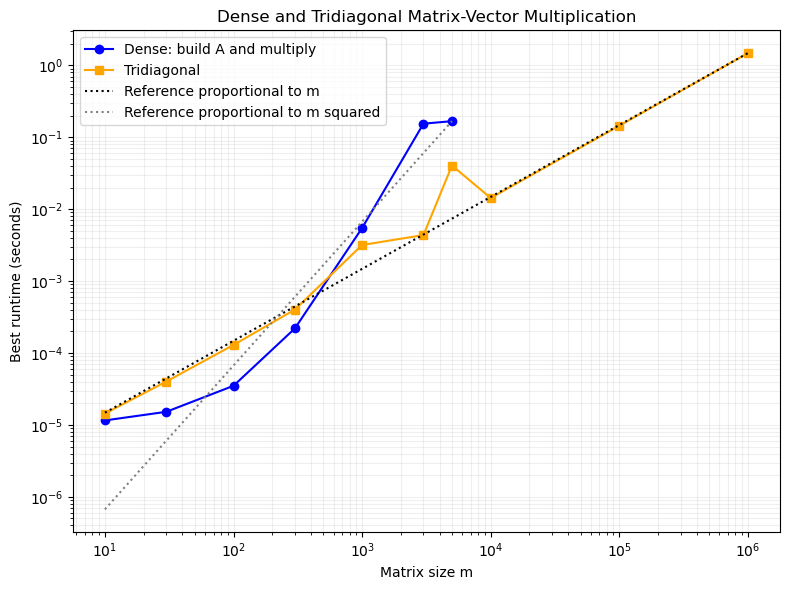

In [5]:
import matplotlib.pyplot as plt
import time

m_dense = [10, 30, 100, 300, 1000, 3000, 5000]
m_tridiag = m_dense + [10000, 100000, 1000000]

num_trials = 5
dense_times = []
tridiag_times = []

for m in m_tridiag:
    a = np.random.randn(m - 1)
    d = np.random.randn(m)
    c = np.random.randn(m - 1)
    v = np.random.randn(m)

    best_dense = np.inf
    best_tridiag = np.inf

    for trial in range(num_trials):
        if m <= 5000:
            tic = time.perf_counter()

            A = np.diag(a, -1) + np.diag(d) + np.diag(c, 1)
            y_dense = A @ v

            toc = time.perf_counter() - tic
            best_dense = min(best_dense, toc)

            del A, y_dense

        tic = time.perf_counter()

        y = tridiag_matvec(a, d, c, v)

        toc = time.perf_counter() - tic
        best_tridiag = min(best_tridiag, toc)

        del y

    tridiag_times.append(best_tridiag)

    if m <= 5000:
        dense_times.append(best_dense)
        print("m =", m,
              "dense time =", best_dense,
              "tridiagonal time =", best_tridiag,
              "speedup =", best_dense / best_tridiag)
    else:
        print("m =", m, "tridiagonal time =", best_tridiag)

# Reference lines proportional to m and m squared
m_ref = np.array(m_tridiag, dtype=float)
linear_ref = tridiag_times[-1] * m_ref / m_ref[-1]

m_ref_dense = np.array(m_dense, dtype=float)
quadratic_ref = dense_times[-1] * (m_ref_dense / m_ref_dense[-1])**2

plt.figure(figsize=(8, 6))

plt.loglog(m_dense, dense_times, 'o-',
           color='blue', label='Dense: build A and multiply')
plt.loglog(m_tridiag, tridiag_times, 's-',
           color='orange', label='Tridiagonal')
plt.loglog(m_ref, linear_ref, ':',
           color='black', label='Reference proportional to m')
plt.loglog(m_ref_dense, quadratic_ref, ':',
           color='gray', label='Reference proportional to m squared')

plt.xlabel('Matrix size m')
plt.ylabel('Best runtime (seconds)')
plt.title('Dense and Tridiagonal Matrix-Vector Multiplication')
plt.grid(True, which='both', alpha=0.2)
plt.legend()
plt.tight_layout()
plt.savefig('runtime_comparison.png', dpi=300, bbox_inches='tight')
plt.show()